## Demo: Model Predictions 

Kim Nguyen
November 15, 2026

This notebook tests whether our model can recognize exercises in video clips it has never seen. It is the evidence of progress for our mid project presentation.

**What it does:**
1. Loads the shared ResNet50 features and splits from Aylie's data preparation notebook (16 frames per clip)

2. Trains our best model so far: a GRU with 192 hidden units, which was the best setting in Tom's experiments

3. Predicts the exercise for all 151 validation clips and reports the accuracy

4. Shows 10 example predictions and a confusion matrix

The test set is not used here, because it is saved for the final model.

### Check the Environment
- Import TensorFlow, the library we use to build and train the model
- Print the version to make sure it matches the team's environment (2.1.0)

In [12]:
import tensorflow as tf
print(tf.__version__)

2.1.0


### Import Libraries
- **numpy** works with the arrays of numbers 
- **pandas** builds the results table at the end

In [13]:
import numpy as np
import pandas as pd

### Load the Data
- Load the shared ResNet50 features and labels from Aylie's data preparation notebook
- Each clip is already turned into 32 frames × 2,048 numbers
- `[:, ::2]` keeps every 2nd frame, so each clip has **16 frames**, same as the base model
- **Training:** 552 clips to learn from · **Validation:** 151 clips the model never trains on

In [14]:
D = '../DATA'
splits = np.load(D + '/splits.npz')

X_train = np.load(D + '/features/resnet50_224_train.npy').astype('float32')[:, ::2]
X_val   = np.load(D + '/features/resnet50_224_val.npy').astype('float32')[:, ::2]
y_train = splits['y_train']
y_val   = splits['y_val']

print(X_train.shape, X_val.shape)

(552, 16, 2048) (151, 16, 2048)


### Build the Model
- Set the random seed to 8, the same as the team, so results can be repeated
- **GRU (192 units):** reads the 16 frames in order to learn the movement (Tom's best setting)
- **Dropout (0.5):** randomly switches off half the outputs during training to reduce overfitting
- **Dense (8, softmax):** gives a probability for each of the 8 exercises
- The summary shows about 1.29 million trainable parameters

In [15]:
np.random.seed(8)
tf.random.set_seed(8)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(16, 2048)),
    tf.keras.layers.GRU(192),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(8, activation='softmax')
])
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
gru_1 (GRU)                  (None, 192)               1291392   
_________________________________________________________________
dropout_1 (Dropout)          (None, 192)               0         
_________________________________________________________________
dense_1 (Dense)              (None, 8)                 1544      
Total params: 1,292,936
Trainable params: 1,292,936
Non-trainable params: 0
_________________________________________________________________


### Train the Model
- **Adam** optimizer and **sparse categorical cross entropy** loss, same as the base model
- **Early stopping:** stops when validation loss stops improving for 8 epochs and keeps the best weights
- Training accuracy climbs to 100% while validation accuracy stays near 50% to 55%, which shows overfitting

In [16]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                        restore_best_weights=True)

model.fit(X_train, y_train, validation_data=(X_val, y_val),
          epochs=100, batch_size=32, callbacks=[stop])


Train on 552 samples, validate on 151 samples
Epoch 1/100
552/552 [==============================] - 2s 3ms/sample - loss: 1.5192 - accuracy: 0.4837 - val_loss: 1.6021 - val_accuracy: 0.5033
Epoch 2/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.3371 - accuracy: 0.9076 - val_loss: 1.4900 - val_accuracy: 0.5497
Epoch 3/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.0989 - accuracy: 0.9855 - val_loss: 1.5584 - val_accuracy: 0.5364
Epoch 4/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.0518 - accuracy: 0.9928 - val_loss: 1.6722 - val_accuracy: 0.5232
Epoch 5/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.0260 - accuracy: 0.9964 - val_loss: 1.7844 - val_accuracy: 0.5166
Epoch 6/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.0146 - accuracy: 1.0000 - val_loss: 1.7906 - val_accuracy: 0.5298
Epoch 7/100
552/552 [==============================] - 1s 1ms/sample - loss: 0.0106 

### Predict the Validation Clips
- The model gives a probability for each exercise for all 151 validation clips
- `argmax` picks the exercise with the highest probability as the model's guess
- Compare the guesses with the true labels to get the **validation accuracy (55%)**

In [17]:
probs = model.predict(X_val)
guess = probs.argmax(axis=1)

print('Validation accuracy:', round((guess == y_val).mean() * 100), '%')

Validation accuracy: 55 %


### Example Predictions
- Pick 10 validation clips at random (seed 8, so the same 10 every time)
- For each clip, show the true exercise, the model's guess, how confident it was, and whether it was right
- Count how many were correct (**6 of 10**)

In [18]:
names = ['Squats', 'Lunges', 'Push ups', 'Wall push ups',
         'Pull ups', 'Handstand push ups', 'Jumping jacks', 'Jump rope']

pick = np.random.RandomState(8).choice(len(y_val), 10, replace=False)

rows = []
for i in pick:
    rows.append({
        'Clip': splits['val_paths'][i].split('/')[-1],
        'True exercise': names[y_val[i]],
        'Predicted': names[guess[i]],
        'Confidence': str(round(probs[i].max() * 100)) + '%',
        'Correct?': 'Yes' if guess[i] == y_val[i] else 'No'
    })

table = pd.DataFrame(rows)
print((table['Correct?'] == 'Yes').sum(), 'of 10 correct')
table


6 of 10 correct


,Clip,True exercise,Predicted,Confidence,Correct?
0,v_BodyWeightSquats_g23_c01.avi,Squats,Push ups,38%,No
1,v_HandStandPushups_g23_c05.avi,Handstand push ups,Handstand push ups,57%,Yes
2,v_HandStandPushups_g23_c03.avi,Handstand push ups,Handstand push ups,73%,Yes
3,v_WallPushups_g24_c01.avi,Wall push ups,Squats,84%,No
4,v_JumpRope_g22_c06.avi,Jump rope,Squats,52%,No
5,v_HandStandPushups_g25_c01.avi,Handstand push ups,Squats,72%,No
6,v_HandStandPushups_g22_c04.avi,Handstand push ups,Handstand push ups,54%,Yes
7,v_WallPushups_g25_c01.avi,Wall push ups,Wall push ups,80%,Yes
8,v_PushUps_g25_c03.avi,Push ups,Push ups,70%,Yes
9,v_JumpRope_g24_c04.avi,Jump rope,Jump rope,91%,Yes


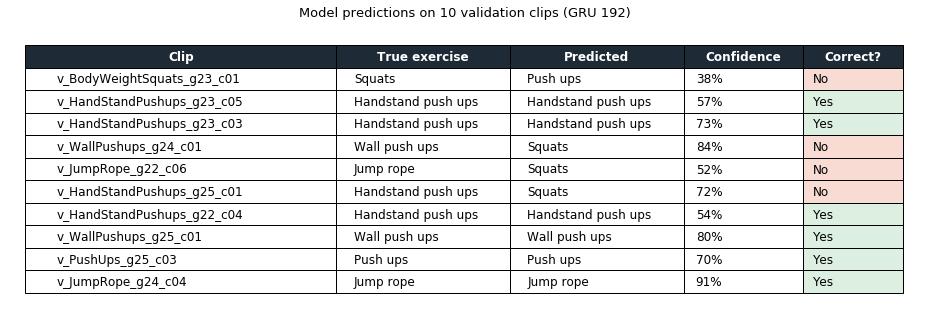

In [19]:
import matplotlib.pyplot as plt

# 1. Remove ".avi" from the clip names so they look cleaner
pic = table.copy()
pic['Clip'] = pic['Clip'].str.replace('.avi', '')

# 2. Make an empty picture and hide the x/y axes
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.axis('off')

# 3. Draw the table
tb = ax.table(cellText=pic.values,
              colLabels=pic.columns,
              colWidths=[0.34, 0.19, 0.19, 0.13, 0.11],
              loc='center', cellLoc='left')
tb.auto_set_font_size(False)
tb.set_fontsize(12)
tb.scale(1, 1.6)

# 4. Color the header dark and the Correct? column green or red
for (r, c), cell in tb.get_celld().items():
    if r == 0:
        cell.set_facecolor('#1F2A37')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    elif c == 4:
        if pic.values[r - 1][4] == 'Yes':
            cell.set_facecolor('#DCEFE0')   # green
        else:
            cell.set_facecolor('#F8DCD3')   # red

# 5. Title, then save and show
ax.set_title('Model predictions on 10 validation clips (GRU 192)', fontsize=13)
plt.tight_layout()
plt.savefig('predictions_table.png', dpi=170)
plt.show()

### Confusion Matrix
- Shows what the model guessed for each exercise across all 151 validation clips
- Rows are the real exercise, columns are the model's guess
- The dark diagonal is correct guesses, everything else is a mix up
- Helps us see which exercises the model struggles with

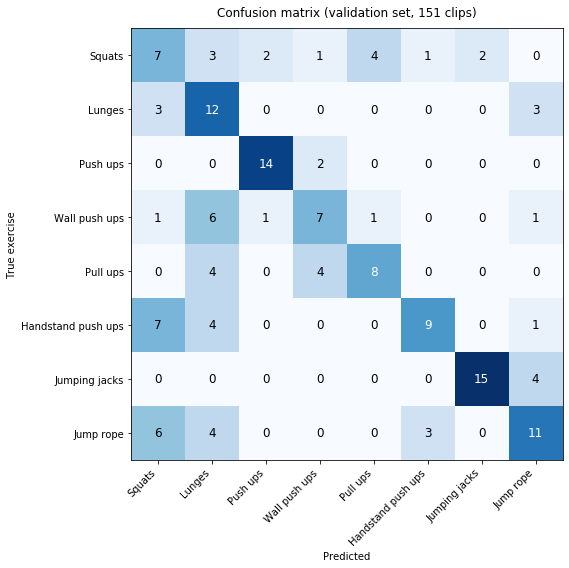

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, guess)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap='Blues')

# write the number inside each square
for r in range(8):
    for c in range(8):
        ax.text(c, r, cm[r, c], ha='center', va='center', fontsize=12,
                color='white' if cm[r, c] > cm.max() / 2 else 'black')

# exercise names on both sides
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_yticklabels(names)
ax.set_xlabel('Predicted')
ax.set_ylabel('True exercise')
ax.set_title('Confusion matrix (validation set, 151 clips)', pad=12)

# fix: show the full top and bottom rows (old matplotlib cuts them in half)
ax.set_ylim(7.5, -0.5)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=170)
plt.show()

### Observations

- The model reached **55% validation accuracy**, the same as Tom's best GRU result, so our results are consistent across laptops.
- Training accuracy hit **100% by epoch 6**, but validation stayed around 50% to 55%. The best epoch was epoch 2. This is clear **overfitting**: the model memorizes the 552 training clips instead of learning the movement.
- In the 10 example clips, it got **6 right**. When it's right it's often confident (jump rope 91%), but it also makes confident mistakes (wall push up called a squat at 84%).
- The confusion matrix shows it does best on **jumping jacks (15 of 19)** and **push ups (14 of 16)**, which have very clear, repeated movements.
- It struggles most with **squats (7 of 20)** and **wall push ups (7 of 17)**. It often confuses **handstand push ups with squats** and **wall push ups with lunges**, so it may rely on the scene or body position more than the actual motion.
- We're still far from our **88% goal**. Next we'll reduce overfitting (dropout, smaller model, soft voting) and then connect the final model to the Streamlit app for the live demo.